# Denoising Diffusion Probabilistic Models (DDPM) — 1D Example
### Following the complete derivation (Ho et al., 2020)

**Data:** 1-D bimodal Gaussian mixture $p(x) = \tfrac{1}{2}\mathcal{N}(-2,\,0.5^2) + \tfrac{1}{2}\mathcal{N}(2,\,0.5^2)$  
**Goal:** Learn to generate samples from $p(x)$ using the DDPM framework.

Sections mirror the derivation document exactly: §1 → §10.

> **Kernel:** use the `jupyter_pytorch` kernel (requires `torch`).

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import norm

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cpu')   # 1-D toy problem — CPU is fine
print('PyTorch version:', torch.__version__, '| device:', device)

PyTorch version: 2.11.0+cpu | device: cpu


## §1  The Naïve Forward Process — Variance Exploding

Start from a clean sample $x_0 \sim p(x)$ and add Gaussian noise of variance $\beta$ at each step:

$$x_t = x_{t-1} + \sqrt{\beta}\,\varepsilon_t, \qquad \varepsilon_t\sim\mathcal{N}(0,\mathbf{I}). \tag{1}$$

Unrolling: $x_t = x_0 + \sqrt{\beta}(\varepsilon_1+\cdots+\varepsilon_t)$, so

$$q(x_t\mid x_0) = \mathcal{N}(x_t;\; x_0,\; t\beta\,\mathbf{I}). \tag{3}$$

The variance $t\beta\to\infty$ — the process **never converges** to $\mathcal{N}(0,\mathbf{I})$.

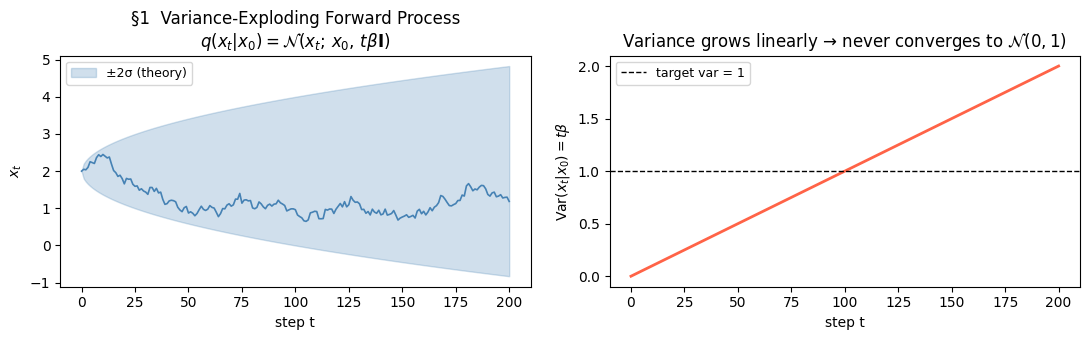

In [2]:
# §1  Variance-exploding demo
beta_naive = 0.01
T_demo     = 200
x0_demo    = np.array([2.0])

x_naive = [x0_demo.copy()]
for _ in range(T_demo):
    x_naive.append(x_naive[-1] + np.sqrt(beta_naive) * np.random.randn(1))
x_naive  = np.array(x_naive).squeeze()
t_vals   = np.arange(T_demo + 1)
var_naive = t_vals * beta_naive

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(t_vals, x_naive, lw=1.2, color='steelblue')
axes[0].fill_between(t_vals,
                     x0_demo[0] - 2*np.sqrt(var_naive),
                     x0_demo[0] + 2*np.sqrt(var_naive),
                     alpha=0.25, color='steelblue', label='±2σ (theory)')
axes[0].set_xlabel('step t'); axes[0].set_ylabel('$x_t$')
axes[0].set_title('§1  Variance-Exploding Forward Process\n'
                  r'$q(x_t|x_0)=\mathcal{N}(x_t;\,x_0,\,t\beta\mathbf{I})$')
axes[0].legend(fontsize=9)

axes[1].plot(t_vals, var_naive, color='tomato', lw=2)
axes[1].set_xlabel('step t'); axes[1].set_ylabel('Var$(x_t|x_0)=t\\beta$')
axes[1].set_title('Variance grows linearly → never converges to $\\mathcal{N}(0,1)$')
axes[1].axhline(1, ls='--', color='k', lw=1, label='target var = 1')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## §2  The Variance-Preserving Forward Process

Scale the previous state before adding noise so that **unit variance is preserved**:

$$q(x_t\mid x_{t-1}) = \mathcal{N}\!\left(x_t;\;\sqrt{1-\beta_t}\,x_{t-1},\;\beta_t\mathbf{I}\right). \tag{4}$$

Define $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s=1}^t \alpha_s$. One step reads:

$$x_t = \sqrt{\alpha_t}\,x_{t-1} + \sqrt{1-\alpha_t}\,\varepsilon_t. \tag{6}$$

**Closed-form marginal** (by induction, eq. 7–10):

$$\boxed{q(x_t\mid x_0) = \mathcal{N}\!\left(x_t;\;\sqrt{\bar\alpha_t}\,x_0,\;(1-\bar\alpha_t)\mathbf{I}\right)} \tag{10}$$

As $t\to T$, $\bar\alpha_t\to 0$ so mean → 0 and variance → 1: $q(x_t\mid x_0)\to\mathcal{N}(0,\mathbf{I})$. ✓

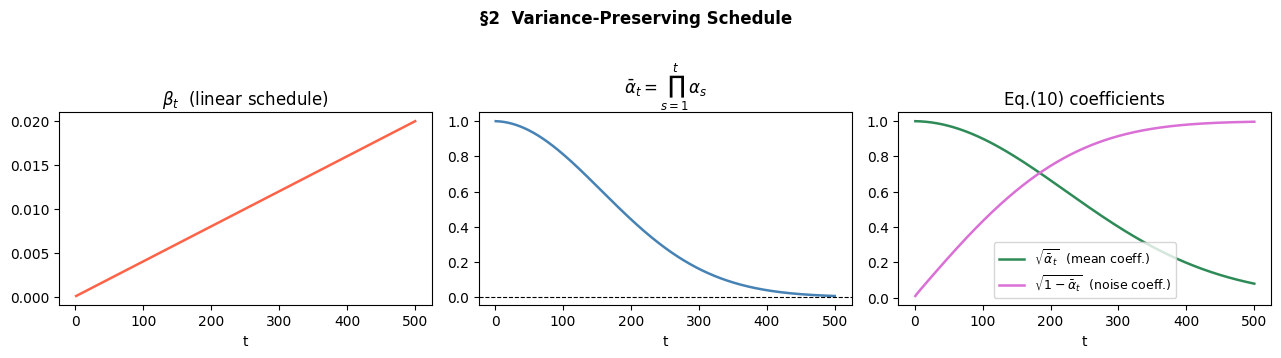

ᾱ_1 = 0.9999   ᾱ_T = 0.006353


In [3]:
# §2  Beta schedule, α_t, ᾱ_t  — eq.(5)
T          = 500
betas      = torch.linspace(1e-4, 0.02, T)           # β_t  linear schedule
alphas     = 1.0 - betas                              # α_t = 1 - β_t
alpha_bars = torch.cumprod(alphas, dim=0)             # ᾱ_t = ∏ α_s
alpha_bars_prev = torch.cat([torch.tensor([1.0]),
                              alpha_bars[:-1]])        # ᾱ_{t-1}

t_axis = np.arange(1, T + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(t_axis, betas.numpy(),       color='tomato',    lw=1.8)
axes[0].set(title=r'$\beta_t$  (linear schedule)', xlabel='t')
axes[1].plot(t_axis, alpha_bars.numpy(),  color='steelblue', lw=1.8)
axes[1].set(title=r'$\bar\alpha_t = \prod_{s=1}^t\alpha_s$', xlabel='t')
axes[1].axhline(0, ls='--', color='k', lw=0.8)
axes[2].plot(t_axis, np.sqrt(alpha_bars.numpy()),   lw=1.8, color='seagreen',
             label=r'$\sqrt{\bar\alpha_t}$  (mean coeff.)')
axes[2].plot(t_axis, np.sqrt(1-alpha_bars.numpy()), lw=1.8, color='orchid',
             label=r'$\sqrt{1-\bar\alpha_t}$  (noise coeff.)')
axes[2].set(title='Eq.(10) coefficients', xlabel='t'); axes[2].legend(fontsize=9)
plt.suptitle('§2  Variance-Preserving Schedule', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()
print(f'ᾱ_1 = {alpha_bars[0]:.4f}   ᾱ_T = {alpha_bars[-1]:.6f}')

### §2  Closed-form forward sample $q(x_t \mid x_0)$ — visualisation

Using eq. (10): sample $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$, $\varepsilon\sim\mathcal{N}(0,1)$.

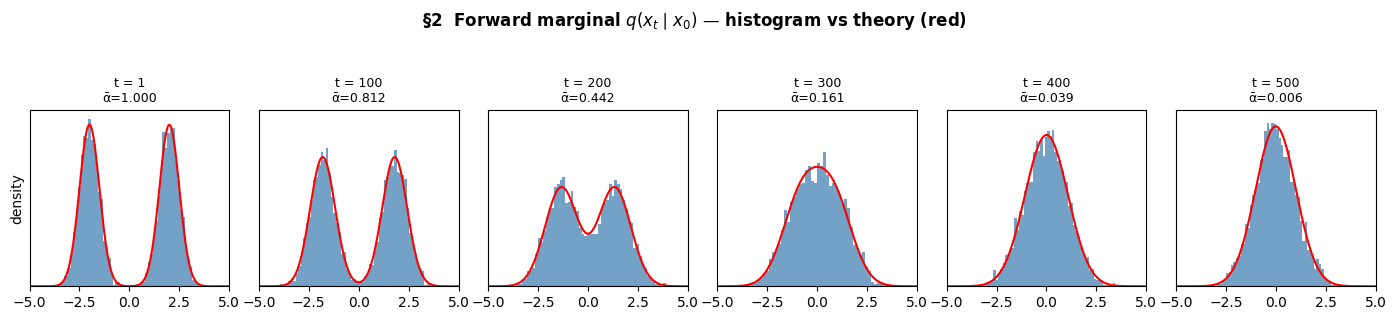

In [4]:
# Data: 1-D bimodal Gaussian mixture  p(x) = 0.5 N(-2,0.5²) + 0.5 N(2,0.5²)
def sample_data(n):
    half = n // 2
    return torch.cat([torch.randn(half)*0.5 - 2.0,
                      torch.randn(n - half)*0.5 + 2.0]).unsqueeze(1)

# Closed-form forward sample  q(x_t | x_0)  — eq.(10)
def q_sample(x0, t_idx, eps=None):
    """x_t = sqrt(ᾱ_t) * x0 + sqrt(1-ᾱ_t) * ε"""
    if eps is None:
        eps = torch.randn_like(x0)
    sqrt_abar   = alpha_bars[t_idx].sqrt().unsqueeze(1)
    sqrt_1mabar = (1 - alpha_bars[t_idx]).sqrt().unsqueeze(1)
    return sqrt_abar * x0 + sqrt_1mabar * eps, eps

# Visualise forward process at selected time steps
N_vis  = 4000
x0_vis = sample_data(N_vis)
t_show = [0, 99, 199, 299, 399, 499]
xgrid  = np.linspace(-5, 5, 300)

fig, axes = plt.subplots(1, len(t_show), figsize=(14, 3), sharey=True)
for ax, t_s in zip(axes, t_show):
    t_idx_vis = torch.full((N_vis,), t_s, dtype=torch.long)
    xt_vis, _ = q_sample(x0_vis, t_idx_vis)
    ax.hist(xt_vis.squeeze().numpy(), bins=60, density=True,
            color='steelblue', alpha=0.75, edgecolor='none')
    ab  = alpha_bars[t_s].item()
    std = np.sqrt(0.25*ab + 1 - ab)   # propagated std of the mixture
    pdf = (0.5*norm.pdf(xgrid, -2*np.sqrt(ab), std) +
           0.5*norm.pdf(xgrid,  2*np.sqrt(ab), std))
    ax.plot(xgrid, pdf, 'r-', lw=1.5)
    ax.set_title(f't = {t_s+1}\nᾱ={ab:.3f}', fontsize=9)
    ax.set_xlim(-5, 5); ax.set_yticks([])
axes[0].set_ylabel('density')
fig.suptitle(r'§2  Forward marginal $q(x_t\mid x_0)$ — histogram vs theory (red)',
             fontweight='bold', y=1.05)
plt.tight_layout(); plt.show()

## §3–§5  Forward / Reverse Joint Distributions & the ELBO

The forward process is a Markov chain:
$$q(x_{1:T}\mid x_0)=\prod_{t=1}^T q(x_t\mid x_{t-1}). \tag{11}$$

The learned reverse process starts from pure noise $p(x_T)=\mathcal{N}(0,\mathbf{I})$:
$$p_\theta(x_{0:T})=p(x_T)\prod_{t=1}^T p_\theta(x_{t-1}\mid x_t). \tag{12}$$

Minimising $-\log p_\theta(x_0)$ is intractable. By Jensen's inequality (ELBO):
$$-\log p_\theta(x_0)\;\le\;\mathbb{E}_q\!\left[-\log\frac{p_\theta(x_{0:T})}{q(x_{1:T}\mid x_0)}\right]=:L. \tag{15}$$

Expanding, applying Bayes' rule + telescoping (§5, eqs. 16–22):
$$L = \mathbb{E}_q\!\Bigl[\underbrace{D_\text{KL}(q(x_T\mid x_0)\|p(x_T))}_{L_T} + \sum_{t=2}^T\underbrace{D_\text{KL}(q(x_{t-1}\mid x_t,x_0)\|p_\theta(x_{t-1}\mid x_t))}_{L_{t-1}} - \underbrace{\log p_\theta(x_0\mid x_1)}_{L_0}\Bigr]. \tag{22}$$

$L_T$ has no trainable parameters; $L_0$ is dropped in practice. We optimise $\sum L_{t-1}$.

## §6  The True Posterior  $q(x_{t-1}\mid x_t, x_0)$

By Bayes' rule $q(x_{t-1}\mid x_t,x_0)\propto q(x_t\mid x_{t-1})\,q(x_{t-1}\mid x_0)$. The log-density is quadratic in $x_{t-1}$, giving a Gaussian $\mathcal{N}(\tilde\mu_t,\tilde\beta_t\mathbf{I})$:

$$\boxed{\tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t} \tag{25}$$

$$\tilde\mu_t = \frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t + \frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0. \tag{26}$$

In [5]:
# §6  True posterior parameters  — eq.(25) & eq.(26)

# β̃_t  — posterior variance  (eq. 25)
beta_tilde    = (1 - alpha_bars_prev) / (1 - alpha_bars) * betas
beta_tilde[0] = betas[0]    # avoid 0/0 at t=1

def posterior_mean(xt, x0, t_idx):
    """μ̃_t(x_t, x_0)  —  eq.(26)"""
    ab   = alpha_bars[t_idx].unsqueeze(1)       # ᾱ_t
    ab_p = alpha_bars_prev[t_idx].unsqueeze(1)  # ᾱ_{t-1}
    bt   = betas[t_idx].unsqueeze(1)
    at   = alphas[t_idx].unsqueeze(1)
    coef_xt = at.sqrt() * (1 - ab_p) / (1 - ab)
    coef_x0 = ab_p.sqrt() * bt / (1 - ab)
    return coef_xt * xt + coef_x0 * x0

# Sanity check: at t=1, μ̃_1 should recover ≈ x0
x0_test = torch.tensor([[2.0]])
t_test  = torch.tensor([0])         # t=1  (0-indexed)
xt_test, _ = q_sample(x0_test, t_test)
mu_test = posterior_mean(xt_test, x0_test, t_test)
print(f'x0 = {x0_test.item():.4f}   x_t(t=1) = {xt_test.item():.4f}')
print(f'μ̃_1 = {mu_test.item():.4f}   (should be ≈ x0 = 2.0)  ✓')

x0 = 2.0000   x_t(t=1) = 2.0049
μ̃_1 = 1.9997   (should be ≈ x0 = 2.0)  ✓


## §7–§8  Gaussian KL → Squared Distance & Noise Reparameterization

Since both Gaussians have **fixed equal variance** $\sigma_t^2$, the KL collapses to (eq. 28):
$$L_{t-1} = \mathbb{E}_q\!\left[\frac{1}{2\sigma_t^2}\|\tilde\mu_t(x_t,x_0)-\mu_\theta(x_t,t)\|^2\right] + C.$$

**Noise reparameterization** (§8, eq. 32–33).  Using $x_0 = \tfrac{1}{\sqrt{\bar\alpha_t}}(x_t - \sqrt{1-\bar\alpha_t}\,\varepsilon)$:
$$\tilde\mu_t = \frac{1}{\sqrt{\alpha_t}}\!\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon\right). \tag{32}$$

We let the network predict the noise and set:
$$\mu_\theta(x_t,t) = \frac{1}{\sqrt{\alpha_t}}\!\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t,t)\right). \tag{33}$$

## §9  Simplified Loss

Draw one random $t$ per step, drop the time-dependent weight:
$$\boxed{L_\text{simple}(\theta) = \mathbb{E}_{t,\,x_0,\,\varepsilon}\!\left[\|\varepsilon - \varepsilon_\theta(\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon,\;t)\|^2\right]} \tag{36}$$

In [6]:
# §8  Precompute sampling coefficients from eq.(32–33) & eq.(37)
sqrt_recip_alphas = (1.0 / alphas).sqrt()              # 1/√α_t
coef_eps          = betas / (1 - alpha_bars).sqrt()    # β_t / √(1-ᾱ_t)
sigma_t           = beta_tilde.sqrt()                  # σ_t = √β̃_t

# ── Network: sinusoidal time embedding + small MLP ────────────────────────────
class SinusoidalTimeEmbedding(nn.Module):
    """Map scalar t ∈ {1,..,T} to a d-dim vector via sin/cos (standard DDPM)."""
    def __init__(self, d=32):
        super().__init__()
        half  = d // 2
        freqs = torch.exp(-np.log(10000) * torch.arange(half).float() / (half - 1))
        self.register_buffer('freqs', freqs)

    def forward(self, t):           # t: (batch,) long
        t = t.float().unsqueeze(1) * self.freqs.unsqueeze(0)   # (B, half)
        return torch.cat([t.sin(), t.cos()], dim=1)             # (B, d)

class NoisePredictor(nn.Module):
    """
    ε_θ(x_t, t) : ℝ × {1,..,T} → ℝ
    Input: x_t (scalar) concatenated with sinusoidal time embedding.
    """
    def __init__(self, time_emb_dim=32, hidden=128):
        super().__init__()
        self.time_emb = SinusoidalTimeEmbedding(time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(1 + time_emb_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden),           nn.SiLU(),
            nn.Linear(hidden, hidden),           nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, xt, t):       # xt: (B,1),  t: (B,) long
        emb = self.time_emb(t)      # (B, time_emb_dim)
        return self.net(torch.cat([xt, emb], dim=1))   # (B, 1)

model = NoisePredictor().to(device)
print(f'Network parameters: {sum(p.numel() for p in model.parameters()):,}')

Network parameters: 37,505


## §10  Training

Repeat until converged (eq. 36):
1. Sample $x_0 \sim p(x)$, $t \sim \mathcal{U}\{1,\dots,T\}$, $\varepsilon \sim \mathcal{N}(0,\mathbf{I})$.
2. Form $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$.
3. Take a gradient step on $\nabla_\theta\|\varepsilon - \varepsilon_\theta(x_t, t)\|^2$.

step   2000/10000   loss = 0.48030
step   4000/10000   loss = 0.44882
step   6000/10000   loss = 0.35908
step   8000/10000   loss = 0.48844
step  10000/10000   loss = 0.49219


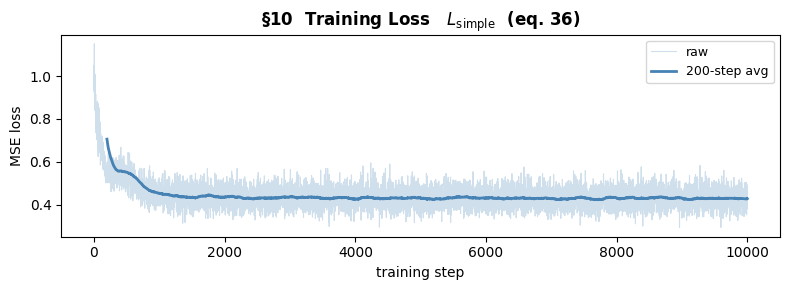

In [7]:
# §10  Training loop — L_simple  (eq. 36)
optimizer    = torch.optim.Adam(model.parameters(), lr=3e-4)
batch_size   = 512
n_steps      = 10_000
log_every    = 2_000
loss_history = []

model.train()
for step in range(1, n_steps + 1):
    # Step 1 — sample x0, t, ε
    x0    = sample_data(batch_size).to(device)                   # (B, 1)
    t_idx = torch.randint(0, T, (batch_size,), device=device)    # uniform {0,..,T-1}
    eps   = torch.randn_like(x0)                                  # ε ~ N(0,I)

    # Step 2 — closed-form forward sample  q(x_t | x_0)  — eq.(10)
    xt, eps = q_sample(x0, t_idx, eps=eps)

    # Step 3 — predict noise and compute L_simple
    eps_pred = model(xt, t_idx)
    loss     = (eps - eps_pred).pow(2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if step % log_every == 0:
        print(f'step {step:>6d}/{n_steps}   loss = {loss.item():.5f}')

# Plot training curve
window   = 200
smoothed = np.convolve(loss_history, np.ones(window)/window, mode='valid')
plt.figure(figsize=(8, 3))
plt.plot(loss_history, alpha=0.25, color='steelblue', lw=0.8, label='raw')
plt.plot(np.arange(window-1, len(loss_history)), smoothed,
         color='steelblue', lw=2, label=f'{window}-step avg')
plt.xlabel('training step'); plt.ylabel('MSE loss')
plt.title('§10  Training Loss   $L_\\mathrm{simple}$  (eq. 36)', fontweight='bold')
plt.legend(fontsize=9); plt.tight_layout(); plt.show()

## §10  Sampling

Start from $x_T \sim \mathcal{N}(0,\mathbf{I})$. For $t = T, \dots, 1$:
1. Draw $z \sim \mathcal{N}(0,\mathbf{I})$ if $t > 1$, else $z = 0$.
2. Update (eq. 37):

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\!\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t, t)\right) + \sigma_t\,z.$$

Return $x_0$.

In [8]:
# §10  Sampling loop — eq.(37)
@torch.no_grad()
def ddpm_sample(n_samples):
    model.eval()
    x = torch.randn(n_samples, 1, device=device)   # x_T ~ N(0, I)
    trajectory = [x.squeeze().cpu().numpy().copy()]

    for t in reversed(range(T)):                   # t = T-1,...,0  (0-indexed)
        t_batch = torch.full((n_samples,), t, dtype=torch.long, device=device)
        eps_hat = model(x, t_batch)

        # Posterior mean  μ_θ  — eq.(33)
        mu = sqrt_recip_alphas[t] * (x - coef_eps[t] * eps_hat)

        # Add posterior noise  σ_t z  (z = 0 at final step)
        x  = mu + (sigma_t[t] * torch.randn_like(x) if t > 0 else 0)

        if t % 100 == 0:
            trajectory.append(x.squeeze().cpu().numpy().copy())

    return x.squeeze().cpu().numpy(), trajectory

n_gen = 4000
samples, traj = ddpm_sample(n_gen)
print(f'Generated {n_gen} samples   mean = {samples.mean():.3f}   std = {samples.std():.3f}')

Generated 4000 samples   mean = 0.045   std = 2.085


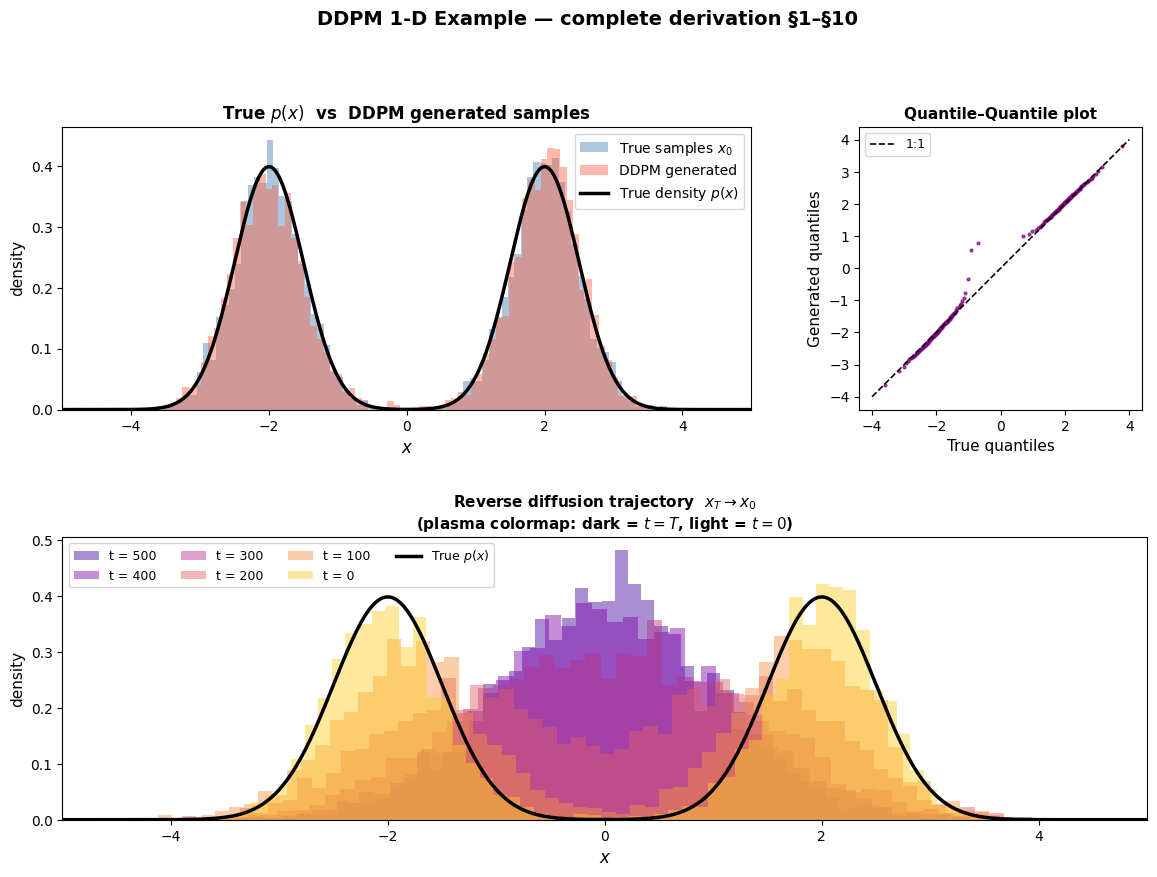

Saved → DDPM_1D_results.png


In [9]:
# Final summary figure
x0_true = sample_data(n_gen).squeeze().numpy()
xgrid   = np.linspace(-5, 5, 500)
p_true  = 0.5*norm.pdf(xgrid, -2, 0.5) + 0.5*norm.pdf(xgrid, 2, 0.5)

fig = plt.figure(figsize=(14, 9))
gs  = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# (a) True vs generated distribution
ax0 = fig.add_subplot(gs[0, :2])
ax0.hist(x0_true, bins=80, density=True, alpha=0.45,
         color='steelblue', label='True samples $x_0$')
ax0.hist(samples,  bins=80, density=True, alpha=0.45,
         color='tomato',    label='DDPM generated')
ax0.plot(xgrid, p_true, 'k-', lw=2.5, label='True density $p(x)$')
ax0.set_xlabel('$x$', fontsize=12); ax0.set_ylabel('density', fontsize=11)
ax0.set_title('True $p(x)$  vs  DDPM generated samples',
              fontsize=12, fontweight='bold')
ax0.legend(fontsize=10); ax0.set_xlim(-5, 5)

# (b) Q-Q plot
ax1 = fig.add_subplot(gs[0, 2])
q_true = np.quantile(np.sort(x0_true), np.linspace(0, 1, 200))
q_gen  = np.quantile(np.sort(samples),  np.linspace(0, 1, 200))
ax1.plot(q_true, q_gen, '.', ms=4, color='purple', alpha=0.7)
ax1.plot([-4, 4], [-4, 4], 'k--', lw=1.2, label='1:1')
ax1.set_xlabel('True quantiles', fontsize=11)
ax1.set_ylabel('Generated quantiles', fontsize=11)
ax1.set_title('Quantile–Quantile plot', fontsize=11, fontweight='bold')
ax1.legend(fontsize=9); ax1.set_aspect('equal')

# (c) Reverse-diffusion trajectory snapshots
t_labels  = [T, 400, 300, 200, 100, 0]
colors_rv = plt.cm.plasma(np.linspace(0.1, 0.9, len(traj)))
ax2 = fig.add_subplot(gs[1, :])
for snap, col, tlbl in zip(traj, colors_rv, t_labels):
    ax2.hist(snap, bins=60, density=True, alpha=0.45,
             color=col, label=f't = {tlbl}')
ax2.plot(xgrid, p_true, 'k-', lw=2.5, label='True $p(x)$', zorder=10)
ax2.set_xlabel('$x$', fontsize=12); ax2.set_ylabel('density', fontsize=11)
ax2.set_title('Reverse diffusion trajectory  $x_T \\to x_0$\n'
              '(plasma colormap: dark = $t=T$, light = $t=0$)',
              fontsize=11, fontweight='bold')
ax2.legend(fontsize=9, ncol=4, loc='upper left'); ax2.set_xlim(-5, 5)

fig.suptitle('DDPM 1-D Example — complete derivation §1–§10',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('DDPM_1D_results.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved → DDPM_1D_results.png')